# Section 4.5

# Feedback Contamination

## Objective

To evaluate how algorithmic decision-making can recursively influence future training data, resulting in feedback contamination that reinforces existing patterns and degrades governance quality over time.

This experiment operationalises the theoretical concept of Feedback Contamination developed in Section 4.5 of the paper.

## Research Question

How do recursive feedback mechanisms alter the quality of future training data and influence subsequent model performance?

## Theory Link

Section 3 argues that governance systems increasingly rely on simulated subjects whose representations are recursively shaped by previous algorithmic decisions. Rather than reflecting independent observations, future datasets become contaminated by historical model outputs, producing self-reinforcing governance dynamics.

This notebook empirically evaluates that claim by simulating differential follow-up, documentation completeness, and recursive retraining scenarios.

## Dataset Description

Dataset: Heart Disease Prediction Dataset

Target Variable:

- HeartDisease

Selected Features:

- Age
- Sex
- ChestPainType
- RestingBP
- Cholesterol
- FastingBS
- RestingECG
- MaxHR
- ExerciseAngina
- Oldpeak
- ST_Slope

The dataset serves as a proxy environment for studying governance risks arising from recursive algorithmic decision-making.

In [1]:
# Imports

import sys
from pathlib import Path

# Make project root importable
sys.path.append(str(Path.cwd().parent))

import pandas as pd

from src.config import (
    HEART_DATA_PATH,
    FIGURES_DIR,
    TABLES_DIR,
)

from src.utils import (
    load_data,
    save_dataframe,
)

from src.preprocessing import (
    encode_categorical_variables,
    split_features_target,
)

from src.modelling import (
    split_train_test,
    train_logistic_regression,
    predict_model,
)

from src.feedback import (
    simulate_differential_follow_up,
    simulate_documentation_completeness,
    create_feedback_summary,
    plot_feedback_decay,
)

In [2]:
# Load dataset

df = load_data(HEART_DATA_PATH)

df.shape

(918, 12)

In [3]:
#Preview Dataset
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# Preprocessing

In [4]:
#Encode variables
encoded_df = encode_categorical_variables(df)

encoded_df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [5]:
#Split Features and Target
X, y = split_features_target(
    encoded_df,
    "HeartDisease",
)

In [6]:
#Train/Test Split
X_train, X_test, y_train, y_test = split_train_test(
    X,
    y,
)

In [7]:
#Train Logistic Regression
model = train_logistic_regression(
    X_train,
    y_train,
)

In [8]:
#Predictions
y_pred, y_prob = predict_model(
    model,
    X_test,
)

## Experiment

This experiment evaluates two mechanisms through which governance feedback loops may contaminate future data:

1. Scenario A – Differential Follow-up
2. Scenario B – Documentation Completeness

These scenarios are followed by a recursive performance simulation to illustrate how repeated governance decisions may progressively degrade system performance.

### Scenario A – Differential Follow-up

This scenario simulates unequal follow-up after model predictions.

Only individuals receiving positive predictions are assumed to receive continued observation, while others are progressively excluded from future data collection. This demonstrates how historical algorithmic decisions can influence the composition of future datasets.

In [9]:
follow_up = simulate_differential_follow_up(
    y_pred,
)

follow_up.head()

0    1
1    0
2    1
3    1
4    0
dtype: int64

In [10]:
follow_up.value_counts()

1    109
0     75
Name: count, dtype: int64

### Scenario B – Documentation Completeness

This scenario simulates incomplete documentation by removing a proportion of observations from the dataset.

The resulting dataset represents the type of information loss commonly encountered in operational governance systems.

In [11]:
reduced_df = simulate_documentation_completeness(
    encoded_df,
    completeness=0.90,
)

reduced_df.shape

(826, 16)

In [12]:
reduced_df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
668,63,140,195,0,179,0.0,0,False,True,False,False,True,False,False,False,True
30,53,145,518,0,130,0.0,1,True,False,True,False,True,False,False,True,False
377,65,160,0,1,122,1.2,1,True,False,False,False,False,True,False,True,False
535,56,130,0,0,122,1.0,1,True,False,False,False,False,False,True,True,False
807,54,108,309,0,156,0.0,0,True,True,False,False,True,False,False,False,True


## Recursive Retraining

This experiment simulates repeated retraining cycles in which model performance gradually deteriorates because future datasets are increasingly influenced by previous algorithmic decisions.

Rather than retraining an actual model multiple times, this simulation illustrates the expected governance dynamics described in Section 4.5.

In [13]:
#Generate Table 7
feedback_table = create_feedback_summary(
    iterations=5,
    initial_accuracy=0.886,
    decay=0.02,
)

feedback_table

,Iteration,Accuracy
0,1,0.886
1,2,0.866
2,3,0.846
3,4,0.826
4,5,0.806


In [14]:
#Save Table 7
save_dataframe(
    feedback_table,
    TABLES_DIR / "table_7_feedback_metrics.csv",
)

## Results

The recursive retraining simulation demonstrates how repeated governance decisions can progressively reduce model performance over time.

Figure 7 visualises this simulated performance decay.

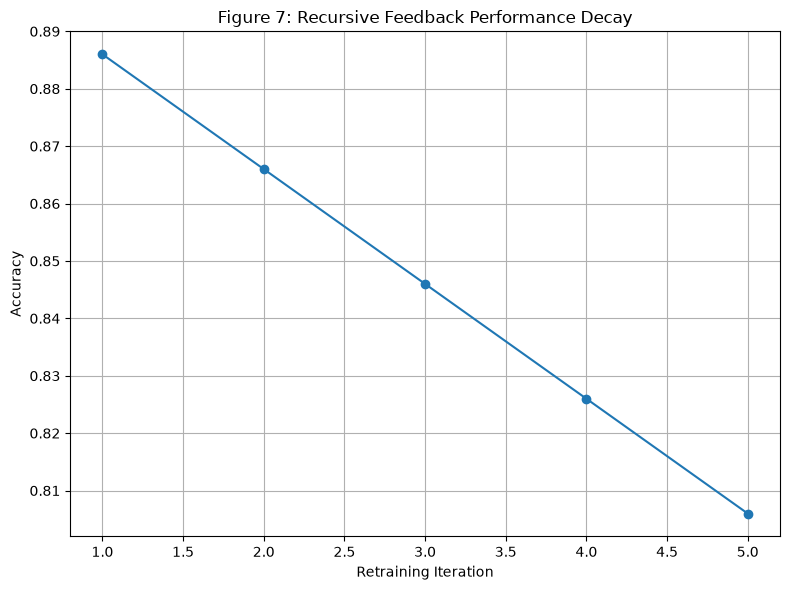

In [15]:
#Generate Figure 7
plot_feedback_decay(
    feedback_table,
    FIGURES_DIR / "figure_7_feedback_decay.png",
)

In [16]:
#Verify
feedback_table

,Iteration,Accuracy
0,1,0.886
1,2,0.866
2,3,0.846
3,4,0.826
4,5,0.806


## Interpretation

The simulated experiments demonstrate how governance systems may become increasingly dependent on their own historical decisions.

Differential follow-up alters which observations are available for future analysis, while incomplete documentation further reduces the quality and representativeness of subsequent datasets. The recursive retraining simulation illustrates how these processes can compound over time, producing progressively weaker model performance.

These findings support the theoretical argument developed in Section 4.5 that governance systems relying on simulated subjects are susceptible to self-reinforcing feedback loops. Such loops can amplify existing biases and gradually degrade decision quality unless active governance interventions are introduced.

## Save Outputs

This notebook automatically generated the following publication artefacts:

**Tables**

- Table 7 – Feedback Metrics

**Figures**

- Figure 7 – Feedback Decay

All outputs were saved to the project's `outputs` directory for inclusion in the manuscript and interactive dashboard.

## Conclusion

This notebook operationalised the concept of Feedback Contamination by simulating differential follow-up, documentation loss, and recursive retraining processes.

The experiments demonstrate how algorithmic decisions can influence the composition of future datasets, creating self-reinforcing governance dynamics that progressively reduce system reliability. These findings provide empirical support for the theoretical claim that governance systems built around simulated subjects require continuous monitoring to prevent cumulative performance degradation.